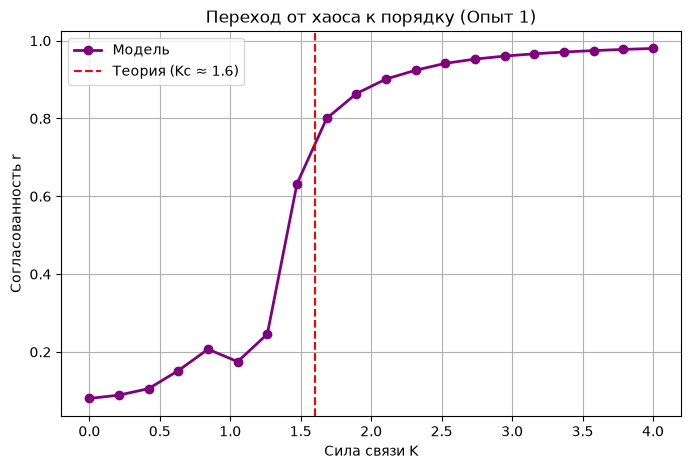

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Параметры модели (из твоего документа)
N = 100
sigma = 1.0
dt = 0.05
time_total = 50  # Время для каждого запуска

# Массив значений K (сила связи) от 0 до 4
K_values = np.linspace(0, 4, 20) 
r_means = [] # Сюда будем собирать средние значения r

# Фиксируем случайность, чтобы график был стабильным
rng = np.random.default_rng(seed=42)
omega = rng.normal(0, sigma, N)
theta_init = rng.uniform(0, 2*np.pi, N)

# Функция для одного запуска
def run_simulation(K):
    theta = theta_init.copy()
    # Даем системе "успокоиться" (первая половина времени)
    for _ in range(int(time_total / 2 / dt)):
        pull = K * np.mean(np.sin(theta[None, :] - theta[:, None]), axis=1)
        theta += (omega + pull) * dt
        
    # Измеряем r на второй половине времени
    r_vals = []
    for _ in range(int(time_total / 2 / dt)):
        pull = K * np.mean(np.sin(theta[None, :] - theta[:, None]), axis=1)
        theta += (omega + pull) * dt
        r = np.sqrt(np.mean(np.cos(theta))**2 + np.mean(np.sin(theta))**2)
        r_vals.append(r)
        
    return np.mean(r_vals) # Возвращаем среднее r

# Прогоняем симуляцию для каждого K
for K in K_values:
    r_means.append(run_simulation(K))

# --- РИСУЕМ ГРАФИК ---
plt.figure(figsize=(8, 5))
plt.plot(K_values, r_means, 'o-', color='purple', linewidth=2, label='Модель')
# Добавляем линию теоретического порога (Kc = 1.6 * sigma)
plt.axvline(x=1.6*sigma, color='red', linestyle='--', label='Теория (Kc ≈ 1.6)')

plt.title('Переход от хаоса к порядку (Опыт 1)')
plt.xlabel('Сила связи K')
plt.ylabel('Согласованность r')
plt.grid(True)
plt.legend()
plt.show()